# Memoria — Práctica 1, Parte 1
## Símplex combinado y L1-SVM

**índice**

1. **El Símplex.** Explicamos cómo funciona, lo probamos con tres problemas pequeños (uno que empieza con primal, otro con dual y otro que cambia de dual a primal) y lo comparamos con `scipy` en 400 problemas aleatorios.
2. **Los datos.** Generamos los dos grupos de puntos separables.
3. **El problema del L1-SVM.** Lo planteamos como problema de minimización.
4. **El dual.** Lo construimos paso a paso.
5. **La resolución.** Resolvemos el dual con nuestro Símplex, sacamos la recta separadora y comprobamos que es correcta.
6. **El dibujo.** Representamos la solución e interpretamos por qué sale así.
7. **Experimentos extra.**
8. **Conclusiones.**

**Archivos que se usan:** `simplex.py` (el algoritmo), `datos.py` (los puntos), `l1_svm.py` (las matrices del SVM) y `graficas.py` (los dibujos). `scipy` y `scikit-learn` se usan solo para **comprobar** resultados, nunca para resolver.

### 0. Preparación

Importamos las librerías y nuestras funciones. `simplex` es el algoritmo; el resto de funciones solo construyen matrices o dibujan.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog

from simplex import simplex                      # nuestro algoritmo
from datos import generar_datos                  # puntos de las dos clases
from l1_svm import (construir_primal_svm,        # matrices del primal del SVM
                    construir_dual_svm,          # matrices del dual del SVM
                    recuperar_clasificador)      # saca w y b del resultado
from graficas import dibujar_clasificador        # dibuja la recta y los márgenes

np.set_printoptions(precision=4, suppress=True)  # números cortos al imprimir
pd.set_option('display.precision', 4)

## 1. El algoritmo Símplex combinado

### 1.1 Cómo funciona

Se introduce con tres matrices,
$$\max\ (\text{o } \min)\ \ c^\top x \qquad \text{s.a.}\quad Ax\le b,\quad x\ge 0 .$$
En código basta con `simplex(c, A, b, objetivo='max')`. Las restricciones con $\ge$ se meten multiplicadas por $-1$.

A cada restricción se le añade una variable de holgura $s_i\ge0$ para convertirla en igualdad. Por ejemplo, $x_1+x_2\le 4$ pasa a ser $x_1+x_2+s_1=4$. Al principio las variables básicas son las holguras, todas las $x$ valen 0 y la tabla de partida es la propia matriz $[A\,|\,I\,|\,b]$.

**Las dos preguntas de cada iteración.**
* **¿Estamos dentro de la región factible?** Sí, si todos los valores de la columna $b$ de la tabla ($B^{-1}b$) son $\ge 0$.
* **¿Podemos mejorar todavía?** Sí, mientras quede algún valor negativo en el renglón $z$ ($c_B B^{-1}A - c$). Cuando todo el renglón $z$ es $\ge0$, hemos llegado al óptimo.

**Decisión dentro del algoritmo**

| Situación | Método | Quién **sale** de la base | Quién **entra** en la base |
|---|---|---|---|
| Al principio $x=0$ es factible (todos los $b_i\ge0$) | **Símplex primal** | la básica con menor cociente $b_i/a_{ie}$ (solo $a_{ie}>0$): la primera que llegaría a 0 | la variable con $z_j$ **más negativo**: la que más mejora el objetivo por unidad |
| Al principio $x=0$ **no** es factible (algún $b_i<0$) | **Símplex dual** | la básica con $b_i$ **más negativo**: la que más incumple | la variable con menor $\lvert z_j/a_{sj}\rvert$ (solo $a_{sj}<0$): arregla esa fila estropeando lo mínimo el renglón $z$ |
| Durante el dual, todos los $b_i$ pasan a ser $\ge0$ | **se cambia a primal** | (como en el primal) | (como en el primal) |

El **dual** se encarga de llevarnos a la región factible y el **primal** de mejorar dentro de ella. Por eso el algoritmo empieza con uno u otro según el punto de partida, y cambia de dual a primal cuando hace falta.

La nueva tabla se obtiene multiplicando la tabla original por
$$\begin{bmatrix} 1 & c_B B^{-1} \\ 0 & B^{-1} \end{bmatrix},$$
donde $B$ son las columnas de las variables básicas.

con `verbose=True` en cada iteración:
1. la variable que **sale** y la que **entra** (las holguras aparecen como $s_i$);
2. la **nueva base**;
3. la matriz $[\,1\ \ c_BB^{-1};\ 0\ \ B^{-1}]$ (filas y columnas $f_i$ = restricción $i$);
4. la **tabla Símplex**: renglón $z$ arriba y, debajo, $B^{-1}A\ |\ B^{-1}b$.

### 1.2 Una función para dibujar el recorrido

Cuando el problema tiene solo dos variables, podemos dibujar la región factible y los puntos por los que pasa el algoritmo. La siguiente celda solo define la función de dibujo; no resuelve nada.

In [2]:
def dibujar_recorrido(A, b, c, historial, titulo, lim=(0, 7)):
    # Rejilla de puntos para pintar la región factible {Ax <= b, x >= 0}.
    g = np.linspace(*lim, 400)
    X1, X2 = np.meshgrid(g, g)
    factible = (X1 >= 0) & (X2 >= 0)
    for fila, lado in zip(A, b):
        factible &= fila[0] * X1 + fila[1] * X2 <= lado + 1e-9

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.contourf(X1, X2, factible, levels=[0.5, 1], colors=['tab:green'], alpha=0.2)

    # Cada restricción es una recta gris.
    for fila, lado in zip(A, b):
        if abs(fila[1]) > 1e-12:
            ax.plot(g, (lado - fila[0] * g) / fila[1], color='grey', lw=0.8)
        else:
            ax.axvline(lado / fila[0], color='grey', lw=0.8)

    # Puntos visitados: azul si el paso fue primal, rojo si fue dual.
    puntos = np.array([h['x'] for h in historial])
    colores = {'primal': 'tab:blue', 'dual': 'tab:red', 'óptimo': 'black'}
    for k in range(len(puntos) - 1):
        ax.annotate('', puntos[k + 1], puntos[k],
                    arrowprops=dict(arrowstyle='->', lw=1.8,
                                    color=colores[historial[k]['metodo']]))
    for h in historial:
        ax.scatter(*h['x'], color=colores[h['metodo']], zorder=3)
        ax.annotate(f"it. {h['iteracion']}", h['x'], textcoords='offset points', xytext=(6, 6))

    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.set_title(titulo)
    ax.plot([], [], color='tab:blue', label='paso primal')
    ax.plot([], [], color='tab:red', label='paso dual')
    ax.legend(loc='upper right', fontsize=8); ax.grid(alpha=0.25)
    plt.show()


def resumen(historial):
    # Tabla corta con lo que pasó en cada iteración: con qué método se hizo
    # el paso, qué variable salió, cuál entró y cómo quedó la base.
    filas = []
    for k, h in enumerate(historial):
        filas.append({'iteración': k,
                      'método del paso': historial[k - 1]['metodo'] if k > 0 else '(inicio)',
                      'sale': h['sale'] or '', 'entra': h['entra'] or '',
                      'nueva base': ', '.join(h['base']), 'objetivo': h['valor']})
    return pd.DataFrame(filas)

### 1.3 Caso A: $x=0$ es factible → Símplex primal

$$\max\ 3x_1+5x_2 \quad\text{s.a.}\quad x_1\le 4,\quad 2x_2\le 12,\quad 3x_1+2x_2\le 18,\quad x\ge 0.$$

Todos los $b_i$ son positivos, así que el punto $(0,0)$ es factible y el algoritmo debe empezar con el **primal**. La siguiente celda introduce las matrices, resuelve imprimiendo todas las iteraciones y después dibuja el recorrido.

In [3]:
# Datos del problema en forma matricial: max c^T x  s.a.  A x <= b.
c = np.array([3, 5])
A = np.array([[1, 0],
              [0, 2],
              [3, 2]])
b = np.array([4, 12, 18])

res = simplex(c, A, b, objetivo='max', verbose=True)

Base inicial: ['s1', 's2', 's3']

  Matriz [1  c_B B^-1 ; 0  B^-1]:
                    f1      f2      f3
     z       1       0       0       0
    f1       0       1       0       0
    f2       0       0       1       0
    f3       0       0       0       1

  Tabla Símplex:
            x1      x2      s1      s2      s3       b
     z      -3      -5       0       0       0       0
    s1       1       0       1       0       0       4
    s2       0       2       0       1       0      12
    s3       3       2       0       0       1      18

Iteración 1
  Sale:  s2
  Entra: x2
  Nueva base: ['s1', 'x2', 's3']

  Matriz [1  c_B B^-1 ; 0  B^-1]:
                    f1      f2      f3
     z       1       0     2.5       0
    f1       0       1       0       0
    f2       0       0     0.5       0
    f3       0       0      -1       1

  Tabla Símplex:
            x1      x2      s1      s2      s3       b
     z      -3       0       0     2.5       0      30
    s1       1  

Solución: x = [2. 6.]   valor óptimo = 36.0


,iteración,método del paso,sale,entra,nueva base,objetivo
0,0,(inicio),,,"s1, s2, s3",0.0
1,1,primal,s2,x2,"s1, x2, s3",30.0
2,2,primal,s3,x1,"s1, x2, x1",36.0


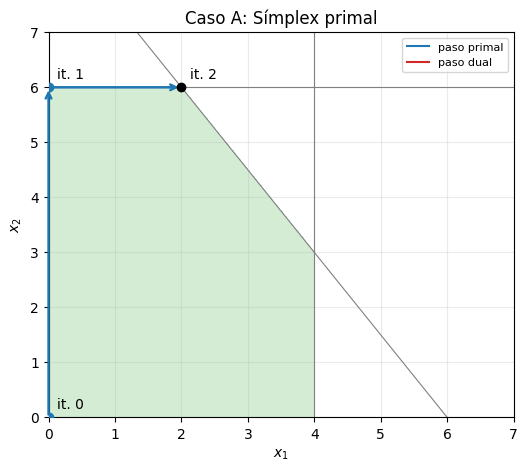

In [4]:
# Resumen de las iteraciones y dibujo del camino seguido.
print('Solución: x =', res['x'], '  valor óptimo =', res['valor'])
display(resumen(res['historial']))
dibujar_recorrido(A, b, c, res['historial'], 'Caso A: Símplex primal')

* Primero entra $x_2$, porque su $z_j=-5$ es el más negativo. Sale $s_2$, que es la restricción que antes se agota ($12/2=6$).
* Después entra $x_1$ y sale $s_3$.
* En la última tabla todo el renglón $z$ es $\ge0$, así que es el óptimo: $x=(2,6)$ con valor 36.

En el dibujo el primal va siempre por vértices de la región verde y nunca sale de la zona factible.

### 1.4 Caso B: $x=0$ no es factible → Símplex dual

$$\min\ 2x_1+3x_2 \quad\text{s.a.}\quad x_1+x_2\ge 4,\quad x_1+3x_2\ge 6,\quad x\ge 0.$$

Esperamos q las restricciones son de tipo $\ge$, así que las metemos multiplicadas por $-1$: $-x_1-x_2\le-4$ y $-x_1-3x_2\le-6$. Ahora hay $b_i$ negativos, por lo que $(0,0)$ no es factible y el algoritmo debe empezar con el **dual**.

In [5]:
# Las restricciones >= se introducen multiplicadas por -1.
c = np.array([2, 3])
A = np.array([[-1, -1],
              [-1, -3]])
b = np.array([-4, -6])

res = simplex(c, A, b, objetivo='min', verbose=True)

Base inicial: ['s1', 's2']

  Matriz [1  c_B B^-1 ; 0  B^-1]:
                    f1      f2
     z       1       0       0
    f1       0       1       0
    f2       0       0       1

  Tabla Símplex:
            x1      x2      s1      s2       b
     z       2       3       0       0       0
    s1      -1      -1       1       0      -4
    s2      -1      -3       0       1      -6

Iteración 1
  Sale:  s2
  Entra: x2
  Nueva base: ['s1', 'x2']

  Matriz [1  c_B B^-1 ; 0  B^-1]:
                    f1      f2
     z       1       0       1
    f1       0       1  -0.333
    f2       0       0  -0.333

  Tabla Símplex:
            x1      x2      s1      s2       b
     z       1       0       0       1      -6
    s1  -0.667       0       1  -0.333      -2
    x2   0.333       1       0  -0.333       2

Iteración 2
  Sale:  s1
  Entra: x1
  Nueva base: ['x1', 'x2']

  Matriz [1  c_B B^-1 ; 0  B^-1]:
                    f1      f2
     z       1     1.5     0.5
    f1       0    

Solución: x = [3. 1.]   valor mínimo = 9.0


,iteración,método del paso,sale,entra,nueva base,objetivo
0,0,(inicio),,,"s1, s2",0.0
1,1,dual,s2,x2,"s1, x2",6.0
2,2,dual,s1,x1,"x1, x2",9.0


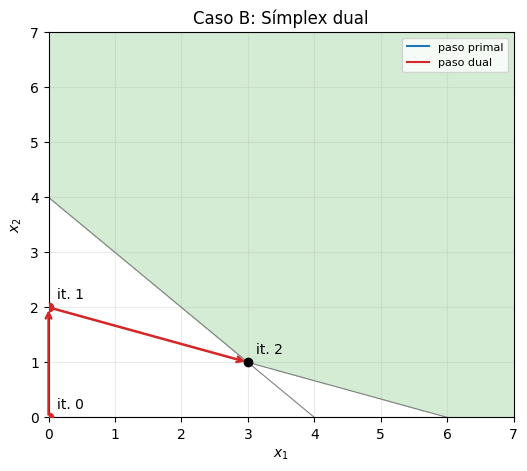

In [6]:
print('Solución: x =', res['x'], '  valor mínimo =', res['valor'])
display(resumen(res['historial']))
dibujar_recorrido(A, b, c, res['historial'], 'Caso B: Símplex dual')

* Primero sale $s_2$, que tiene el $b$ más negativo ($-6$), y entra la variable con menor $|z_j/a_{sj}|$.
* En la siguiente iteración se corrige la otra fila negativa.
* Cuando todos los $b_i$ son $\ge0$, el renglón $z$ ya es $\ge0$, así que se llega directamente al óptimo: $x=(3,1)$ con coste 9.

En el dibujo se ve la diferencia con el caso A: el dual pasa por puntos de **fuera** de la región verde y "entra" en ella justo al final.

### 1.5 Caso C: el algoritmo cambia de dual a primal

$$\max\ x_1+x_2 \quad\text{s.a.}\quad x_1+x_2\ge 2,\quad x_1\le 3,\quad x_2\le 3,\quad x\ge 0.$$

La primera restricción hace que $(0,0)$ no sea factible ($b_1=-2$), así que se empieza con el **dual**. Pero en cuanto el punto sea factible todavía se podrá mejorar (queremos $x_1$ y $x_2$ lo más grandes posible), así que el algoritmo tendrá que **cambiar a primal**

In [ ]:
c = np.array([1, 1])
A = np.array([[-1, -1],# x1 + x2 >= 2, multiplicada por -1
              [ 1,  0],
              [ 0,  1]])
b = np.array([-2, 3, 3])

res = simplex(c, A, b, objetivo='max', verbose=True)

Base inicial: ['s1', 's2', 's3']

  Matriz [1  c_B B^-1 ; 0  B^-1]:
                    f1      f2      f3
     z       1       0       0       0
    f1       0       1       0       0
    f2       0       0       1       0
    f3       0       0       0       1

  Tabla Símplex:
            x1      x2      s1      s2      s3       b
     z      -1      -1       0       0       0       0
    s1      -1      -1       1       0       0      -2
    s2       1       0       0       1       0       3
    s3       0       1       0       0       1       3

Iteración 1
  Sale:  s1
  Entra: x1
  Nueva base: ['x1', 's2', 's3']

  Matriz [1  c_B B^-1 ; 0  B^-1]:
                    f1      f2      f3
     z       1      -1       0       0
    f1       0      -1       0       0
    f2       0       1       1       0
    f3       0       0       0       1

  Tabla Símplex:
            x1      x2      s1      s2      s3       b
     z       0       0      -1       0       0       2
    x1       1  

Solución: x = [3. 3.]   valor óptimo = 6.0


,iteración,método del paso,sale,entra,nueva base,objetivo
0,0,(inicio),,,"s1, s2, s3",0.0
1,1,dual,s1,x1,"x1, s2, s3",2.0
2,2,primal,s2,s1,"x1, s1, s3",3.0
3,3,primal,s3,x2,"x1, s1, x2",6.0


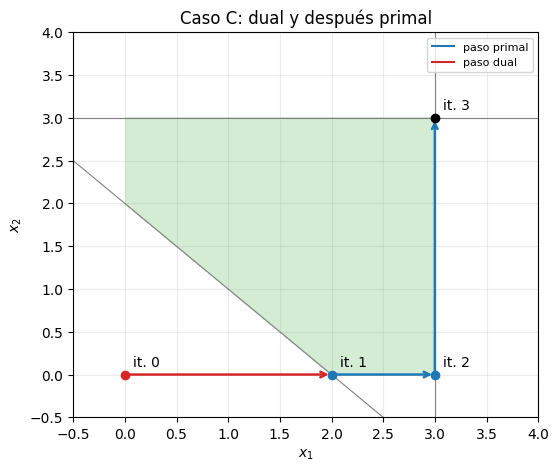

In [8]:
print('Solución: x =', res['x'], '  valor óptimo =', res['valor'])
display(resumen(res['historial']))
dibujar_recorrido(A, b, c, res['historial'], 'Caso C: dual y después primal', lim=(-0.5, 4))

* La iteración 1 es **dual**: sale $s_1$ y el punto pasa a $(2,0)$, que ya es factible.
* El renglón $z$ todavía tiene negativos, así que el algoritmo **cambia a primal** y hace dos iteraciones más hasta el óptimo $(3,3)$ con valor 6.

En la columna "método del paso" del resumen se ve el cambio de dual a primal.

### 1.6 Problemas sin solución

Hay dos situaciones en las que el algoritmo debe avisar de que no hay solución:
* **Infactible**: en el dual, una fila con $b_i<0$ no tiene ningún coeficiente negativo, así que no hay forma de arreglarla.
* **No acotado**: en el primal, la variable que entra no tiene ningún $a_{ie}>0$, así que puede crecer sin límite.

La siguiente celda prueba un ejemplo de cada caso.

In [9]:
# Infactible: x1 + x2 <= 1 y x1 + x2 >= 3 a la vez.
try:
    simplex([1, 1], [[1, 1], [-1, -1]], [1, -3], objetivo='min')
except ValueError as e:
    print('Infactible  ->', e)

# No acotado: max x1 + x2 con solo x1 - x2 <= 1 (x2 puede crecer sin límite).
try:
    simplex([1, 1], [[1, -1]], [1], objetivo='max')
except ValueError as e:
    print('No acotado  ->', e)

Infactible  -> Problema infactible.
No acotado  -> Problema no acotado.


### 1.7 Comprobación con 400 problemas aleatorios

Pra probar su corecto funcionamiento, generamos 400 problemas al azar. Unos empiezan con primal, otros con dual, y algunos no tienen solución. Cada uno se resuelve con nuestro Símplex y con el de `scipy` (`linprog`), y contamos en cuántos coinciden el resultado y el valor óptimo. Aquí no se imprimen las iteraciones (`verbose=False`), porque serían miles de tablas.

In [ ]:
rng = np.random.default_rng(2024) # semilla fija: siempre salen los mismos problemas
filas = []
for _ in range(400):
    # Problema aleatorio con 4 restricciones y 5 variables
    A = rng.uniform(-3, 3, (4, 5))
    b = rng.uniform(-3, 5, 4)
    c = rng.uniform(-3, 3, 5)
    objetivo = 'max'
    if rng.random() < 0.4: # 40 %: minimizaciones con restricciones >=
        objetivo = 'min'
        c, A, b = np.abs(c), -np.abs(A), -np.abs(b)

    # Referencia: scipy (minimiza, así que para max se cambia el signo de c)
    ref = linprog(c if objetivo == 'min' else -c, A_ub=A, b_ub=b,
                  method='highs', options={'presolve': False})

    # Nuestro Símplex
    try:
        res = simplex(c, A, b, objetivo)
        arranque = res['historial'][0]['metodo']
        resultado = 'óptimo'
        if ref.status == 0:
            valor_ref = ref.fun if objetivo == 'min' else -ref.fun
            coincide = abs(res['valor'] - valor_ref) < 1e-6
        else:
            coincide = False
    except ValueError as e:
        arranque = 'primal' if np.all(b >= 0) else 'dual'
        resultado = 'no acotado' if 'acotado' in str(e) else 'infactible'
        coincide = ref.status == {'infactible': 2, 'no acotado': 3}[resultado]
    filas.append({'arranque': arranque, 'resultado': resultado, 'coincide': coincide})

tabla = pd.DataFrame(filas)
display(pd.crosstab(tabla['arranque'], tabla['resultado'], margins=True, margins_name='total'))
print(f"Coinciden con scipy: {tabla['coincide'].sum()} de {len(tabla)}")

resultado,infactible,no acotado,óptimo,total
arranque,,,,
dual,43,89,226,358
primal,0,28,14,42
total,43,117,240,400


Coinciden con scipy: 400 de 400


### Conclusiones del apartado 1

El problema se introduce de forma **matricial**, con `c`, `A` y `b`, como en un programa comercial. El algoritmo decide solo cómo empezar: con el Símplex **primal** cuando $x=0$ es factible (caso A) y con el Símplex **dual** cuando no lo es (caso B). Además, **cambia** de dual a primal cuando hace falta (caso C).

Para comprobar que funciona, lo hemos probado con 400 problemas aleatorios y en todos da el mismo resultado que `scipy`: el mismo valor óptimo o, si no hay solución, el mismo diagnóstico.

Como indican los apuntes, el algoritmo combinado tiene límites ya q no trata casos degenerados y, si la tabla de partida no es factible ni para el primal ni para el dual, la regla del dual no garantiza que converja

## 2. Generación de los datos

Creamos dos grupos de 12 puntos en el plano:
* clase $-1$ alrededor de $(-2,-1.5)$;
* clase $+1$ alrededor de $(2,1.5)$.

Los puntos están poco dispersos (desviación 0.35) y los centros muy separados, así que se puede trazar una recta que separa los dos grupos. La semilla es fija para que salgan siempre los mismos puntos.

24 puntos en 2 dimensiones: 12 de la clase -1 y 12 de la clase +1


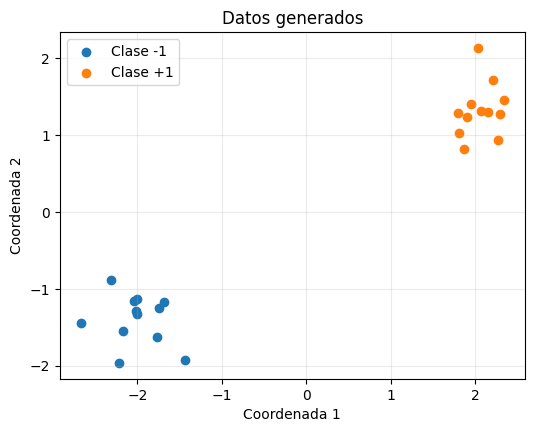

In [ ]:
X, y = generar_datos() # X: coordenadas de los puntos, y: su clase (-1 o +1)
n, d = X.shape # n = num de puntos, d = num de coordenadas (2)
print(f'{n} puntos en {d} dimensiones: {np.sum(y == -1)} de la clase -1 y {np.sum(y == 1)} de la clase +1')

plt.figure(figsize=(6, 4.5))
plt.scatter(*X[y == -1].T, c='tab:blue', label='Clase -1')
plt.scatter(*X[y == 1].T, c='tab:orange', label='Clase +1')
plt.xlabel('Coordenada 1'); plt.ylabel('Coordenada 2')
plt.title('Datos generados'); plt.legend(); plt.grid(alpha=0.25); plt.show()

Los datos cumplen lo que pide el enunciado: son de dos dimensiones, hay dos clases y a simple vista se pueden separar con una recta. Lo **confirmaremos** en el apartado 5, porque ningún punto necesitará holgura ($\xi_i=0$).

También se ve que las nubes están más separadas en horizontal (unas 4 unidades) que en vertical (unas 3). Esto será importante en los apartados siguientes

## 3. El problema de minimización del L1-SVM

Buscamos una recta $w_1x_1+w_2x_2+b=0$ que deje cada clase a un lado, con la mayor distancia posible a los puntos (el **margen**). Para cada punto $(x_i,y_i)$ pedimos que
$$y_i\,(w^\top x_i+b)\ \ge\ 1-\xi_i ,\qquad \xi_i\ge0 .$$

* Si el punto está bien clasificado y fuera del margen, se cumple con $\xi_i=0$.
* $\xi_i$ es la **holgura**: lo que "perdonamos" a un punto que se mete en el margen. Cada unidad de holgura se paga con una penalización $C$.

**El problema** es minimizar el tamaño de $w$ (cuanto más pequeño, más ancho es el margen) más las penalizaciones:
$$\min\ \ \|w\|_1 + C\sum_i \xi_i \qquad \text{donde } \|w\|_1=|w_1|+|w_2| .$$

El SVM clásico usa $w_1^2+w_2^2$, que es una función cuadrática, y no se puede resolver con el Símplex. Con valores absolutos sí, gracias a la propiedad de escribir cada número como diferencia de dos positivos,
$$w=w^+-w^-,\qquad b=b^+-b^-,\qquad \text{con todas las partes}\ \ge 0 .$$
Así $|w_j|=w_j^++w_j^-$ y todo queda **lineal**. Las restricciones $\ge$ se multiplican por $-1$ para dejarlas en forma $\le$.

Cada celda construye las matrices `c, A, b` del primal con `construir_primal_svm` y muestra su tamaño. Su resolución se hará en próximos apartados

In [12]:
C = 10.0   # penalización de las holguras; grande porque los datos son separables

# Variables del primal: (w1+, w2+, w1-, w2-, b+, b-, xi_1, ..., xi_n).
c_p, A_p, b_p = construir_primal_svm(X, y, C)
print('Primal: A tiene', A_p.shape[0], 'filas (una por punto) y', A_p.shape[1], 'columnas (variables)')
print('Todos los b valen -1 -> x = 0 no es factible -> este problema empezará con Símplex DUAL')

Primal: A tiene 24 filas (una por punto) y 30 columnas (variables)
Todos los b valen -1 -> x = 0 no es factible -> este problema empezará con Símplex DUAL


## 4. El problema dual

A cada restricción del primal (una por punto) le asociamos una variable $\alpha_i\ge0$. Intuitivamente, $\alpha_i$ mide **cuánto "empuja" el punto $i$ a la recta**: los puntos alejados no empujan ($\alpha_i=0$) y los que están justo en el borde del margen sí ($\alpha_i>0$). Esos últimos son los **vectores soporte**.

Se obtiene con el lagrangiano. Se mira qué condiciones deben cumplir las $\alpha$ para que el primal no pueda bajar sin límite al moverse cada una de sus variables.

| Variable del primal | Condición que aparece en el dual |
|---|---|
| $w_j$ (con valor absoluto en el objetivo) | $-1\le \sum_i \alpha_i y_i x_{ij}\le 1$ |
| $b$ (libre y sin coste) | $\sum_i \alpha_i y_i = 0$ |
| $\xi_i$ (con coste $C$) | $0\le\alpha_i\le C$ |

El **dual del L1-SVM** queda así:
$$\max\ \sum_i\alpha_i\quad\text{s.a.}\quad -1\le\sum_i\alpha_iy_ix_{ij}\le1,\qquad \sum_i\alpha_iy_i=0,\qquad 0\le\alpha_i\le C .$$

**En forma matricial** (con todas las restricciones en forma $\le$, para nuestro Símplex):

| Filas | Restricción | Cuántas |
|---|---|---|
| 1 a $d$ | $\sum_i\alpha_iy_ix_{ij}\le 1$ | $d=2$ |
| $d{+}1$ a $2d$ | $-\sum_i\alpha_iy_ix_{ij}\le 1$ | $2$ |
| $2d{+}1$ | $\sum_i\alpha_iy_i\le0$ | 1 |
| $2d{+}2$ | $-\sum_i\alpha_iy_i\le0$ | 1 |
| resto | $\alpha_i\le C$ | $n=24$ |

La igualdad $\sum\alpha_iy_i=0$ se escribe como dos desigualdades ($\le0$ y $\ge0$), porque el algoritmo combinado no admite igualdades.

Para sacar la recta nos basamos en que el dual del dual es otra vez el primal. En la práctica significa que, al terminar, el vector $c_BB^{-1}$ (la fila $z$ de la matriz $[1\ c_BB^{-1};\ 0\ B^{-1}]$) contiene **una componente por restricción**, y esas componentes son las variables del primal en el mismo orden que las filas de la tabla anterior: $w^+$, $w^-$, $b^+$, $b^-$, $\xi$. Es decir, **resolviendo el dual obtenemos también $w$ y $b$**, sin resolver nada más.

Construyimos `c, A, b` del dual y muestra su tamaño:

In [13]:
# Variables del dual: alpha_1, ..., alpha_n (en las tablas aparecen como x1, ..., x24).
c_d, A_d, b_d = construir_dual_svm(X, y, C)
print('Dual: A tiene', A_d.shape[0], 'filas (restricciones) y', A_d.shape[1], 'columnas (una alpha por punto)')
print('Todos los b son >= 0 -> x = 0 es factible -> este problema empezará con Símplex PRIMAL')

Dual: A tiene 30 filas (restricciones) y 24 columnas (una alpha por punto)
Todos los b son >= 0 -> x = 0 es factible -> este problema empezará con Símplex PRIMAL


### Conclusiones del apartado 4

El dual tiene una variable $\alpha_i$ por punto y $2d+2+n=30$ restricciones. Como todos sus $b$ son $\ge0$, empezará con el **primal**, al contrario que el problema del apartado 3. Así el propio SVM sirve para ver los dos arranques del algoritmo.

## 5. Resolución del dual con nuestro Símplex

**Qué hacemos.** Resolvemos el dual imprimiendo todas las iteraciones. En las tablas, `x1 … x24` son las $\alpha_1 \dots \alpha_{24}$ y `s1 … s30` las holguras de las 30 restricciones.

Las tablas son anchas (30 filas y 54 columnas) y conviene desplazarse en horizontal para verlas enteras. Al final, la fila `z` de la última matriz $[1\ c_BB^{-1};\ 0\ B^{-1}]$ contiene $c_BB^{-1}$, de donde sacaremos $w$ y $b$.

In [14]:
res_dual = simplex(c_d, A_d, b_d, objetivo='max', verbose=True)

Base inicial: ['s1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21', 's22', 's23', 's24', 's25', 's26', 's27', 's28', 's29', 's30']

  Matriz [1  c_B B^-1 ; 0  B^-1]:
                    f1      f2      f3      f4      f5      f6      f7      f8      f9     f10     f11     f12     f13     f14     f15     f16     f17     f18     f19     f20     f21     f22     f23     f24     f25     f26     f27     f28     f29     f30
     z       1       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0
    f1       0       1       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0 

**Qué hacemos ahora.** Leemos el resultado:
* las $\alpha_i$ son la solución $x$ del dual;
* $w$, $b$ y $\xi$ salen de $c_BB^{-1}$ con `recuperar_clasificador`.

In [ ]:
alpha = res_dual['x'] # solución del dual
cB_Binv = res_dual['multiplicadores'] # fila z de la última matriz

# c_B B^-1 = (w1+, w2+, w1-, w2-, b+, b-, xi_1, ..., xi_n)
w, b_svm, xi = recuperar_clasificador(cB_Binv, d, n)

print('Resumen de las iteraciones:')
display(resumen(res_dual['historial']))
print('Valor óptimo del dual (suma de alphas):', round(res_dual['valor'], 6))
print('Recta separadora:  w =', w, '  b =', round(b_svm, 6))
print('¿Todas las holguras xi son 0? ', bool(np.all(xi < 1e-9)), ' -> los datos son separables')

Resumen de las iteraciones:


,iteración,método del paso,sale,entra,nueva base,objetivo
0,0,(inicio),,,"s1, s2, s3, s4, s5, s6, s7, s8, s9, s10, s11, ...",0.0000
1,1,primal,s6,x1,"s1, s2, s3, s4, s5, x1, s7, s8, s9, s10, s11, ...",0.0000
2,2,primal,s1,x13,"x13, s2, s3, s4, s5, x1, s7, s8, s9, s10, s11,...",0.5276
3,3,primal,x1,x3,"x13, s2, s3, s4, s5, x3, s7, s8, s9, s10, s11,...",0.6208


Valor óptimo del dual (suma de alphas): 0.620825
Recta separadora:  w = [0.6208 0.    ]   b = -0.110092
¿Todas las holguras xi son 0?  True  -> los datos son separables


### 5.1 Comprobación 1: el primal da el mismo resultado

Resolvemos el primal del apartado 3 con el mismo Símplex. Esperamos que:
* empiece con **dual**, porque sus $b$ son negativos;
* su valor mínimo coincida con el máximo del dual (dualidad fuerte);
* dé la misma recta.

También se imprimen todas sus iteraciones.

In [16]:
res_primal = simplex(c_p, A_p, b_p, objetivo='min', verbose=True)

Base inicial: ['s1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21', 's22', 's23', 's24']

  Matriz [1  c_B B^-1 ; 0  B^-1]:
                    f1      f2      f3      f4      f5      f6      f7      f8      f9     f10     f11     f12     f13     f14     f15     f16     f17     f18     f19     f20     f21     f22     f23     f24
     z       1       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0
    f1       0       1       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0
    f2       0       0       1       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0       0    

In [17]:
v = res_primal['x']                          # (w+, w-, b+, b-, xi)
w_p = v[:d] - v[d:2*d]                       # w = w+ - w-
b_p = v[2*d] - v[2*d + 1]                    # b = b+ - b-

display(resumen(res_primal['historial']))
display(pd.DataFrame({'valor óptimo': [res_dual['valor'], res_primal['valor']],
                      'w1': [w[0], w_p[0]], 'w2': [w[1], w_p[1]], 'b': [b_svm, b_p]},
                     index=['dual (c_B B^-1)', 'primal (directo)']))
print('Diferencia entre los dos valores óptimos:', abs(res_dual['valor'] - res_primal['valor']))

,iteración,método del paso,sale,entra,nueva base,objetivo
0,0,(inicio),,,"s1, s2, s3, s4, s5, s6, s7, s8, s9, s10, s11, ...",0.0000
1,1,dual,s1,x6,"x6, s2, s3, s4, s5, s6, s7, s8, s9, s10, s11, ...",0.0000
2,2,dual,s13,x1,"x6, s2, s3, s4, s5, s6, s7, s8, s9, s10, s11, ...",0.5276
3,3,dual,s3,s1,"x6, s2, s1, s4, s5, s6, s7, s8, s9, s10, s11, ...",0.6208


,valor óptimo,w1,w2,b
dual (c_B B^-1),0.6208,0.6208,0.0,-0.1101
primal (directo),0.6208,0.6208,0.0,-0.1101


Diferencia entre los dos valores óptimos: 0.0


### 5.2 Comprobación 2: los vectores soporte

Miramos qué puntos tienen $\alpha_i>0$. Según la teoría, deben ser **exactamente** los que quedan sobre el borde del margen, es decir, con $y_i(w^\top x_i+b)=1$. El resto de puntos debe estar más lejos ($>1$).

In [18]:
f = X @ w + b_svm                            # valor de la recta en cada punto
soporte = alpha > 1e-7                       # puntos con alpha > 0

display(pd.DataFrame({'x1': X[soporte, 0], 'x2': X[soporte, 1], 'clase': y[soporte],
                      'alpha': alpha[soporte], 'y·f(x)': y[soporte] * f[soporte]},
                     index=np.flatnonzero(soporte) + 1).rename_axis('punto'))
print('Para el resto de puntos, el menor y·f(x) es', round((y * f)[~soporte].min(), 4), '(> 1)')

,x1,x2,clase,alpha,y·f(x)
punto,,,,,
3,-1.4334,-1.9219,-1.0,0.3104,1.0
13,1.7881,1.2920,1.0,0.3104,1.0


Para el resto de puntos, el menor y·f(x) es 1.0129 (> 1)


### 5.3 Comprobación 3: `scipy` da lo mismo

Resolvemos el mismo dual con `scipy` y comparamos el valor óptimo y la recta que se obtiene de sus multiplicadores.

In [19]:
ref = linprog(-c_d, A_ub=A_d, b_ub=b_d, method='highs')      # scipy minimiza: usamos -c
u = -ref.ineqlin.marginals                                    # equivalente a c_B B^-1
w_ref, b_ref, _ = recuperar_clasificador(u, d, n)
print('Valor óptimo   nuestro Símplex:', round(res_dual['valor'], 8), '  scipy:', round(-ref.fun, 8))
print('Recta          nuestro Símplex: w =', w, ' b =', round(b_svm, 6))
print('               scipy:           w =', w_ref, ' b =', round(b_ref, 6))

Valor óptimo   nuestro Símplex: 0.62082493   scipy: 0.62082493
Recta          nuestro Símplex: w = [0.6208 0.    ]  b = -0.110092
               scipy:           w = [0.6208 0.    ]  b = -0.110092


### Conclusiones del apartado 5

* Nuestro Símplex resuelve el dual del L1-SVM. Empieza con **primal** porque $x=0$ es factible, y llega al óptimo en pocas iteraciones.
* **La recta sale del propio dual**: la fila $z$ de la última matriz ($c_BB^{-1}$) da $w$ y $b$.
* Las tres comprobaciones salen bien:
  1. el primal, que empieza con **dual**, da el mismo valor y la misma recta;
  2. solo los puntos con $\alpha_i>0$ están en el borde del margen;
  3. `scipy` da lo mismo.
* Todas las holguras $\xi_i$ son 0, lo que confirma que los datos son separables.

## 6. Dibujo de la solución

**Qué hacemos.** Dibujamos:
* los puntos;
* la recta separadora $f(x)=0$;
* los bordes del margen $f(x)=\pm1$;
* los vectores soporte, rodeados con un círculo.

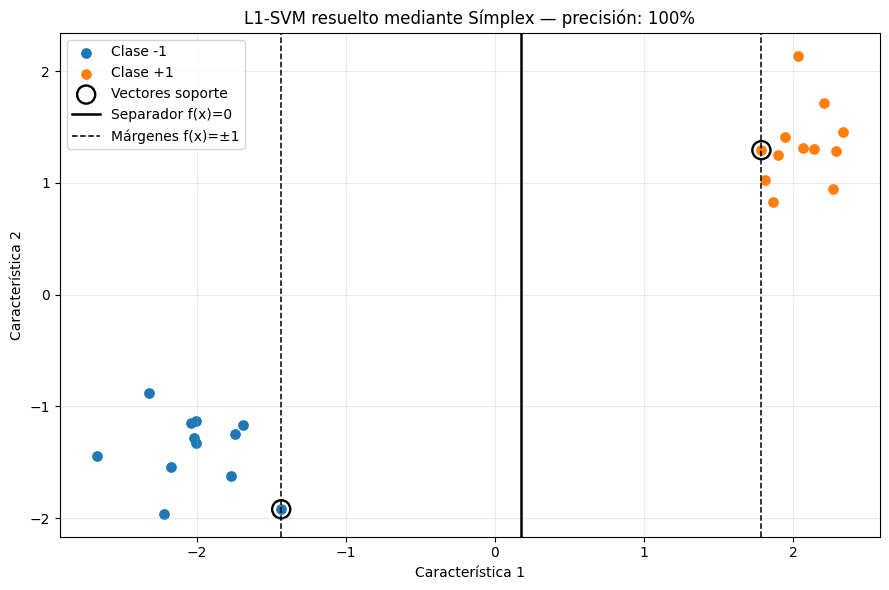

In [20]:
precision = np.mean(np.where(f >= 0, 1, -1) == y)   # % de puntos bien clasificados
dibujar_clasificador(X, y, w, b_svm, alpha, precision)

La recta es vertical y no la "diagonal" que uno esperaría porque la solución tiene $w_2=0$: el modelo **solo usa la primera coordenada**. Es una propiedad conocida de la norma 1:
* Al minimizar $|w_1|+|w_2|$, al modelo le sale más barato poner alguna componente exactamente a 0, si con la otra le basta.
* Geométricamente, el Símplex siempre acaba en un vértice, y en los vértices muchas variables valen 0.
* Como las nubes están más separadas en horizontal, con $x_1$ es suficiente.

Por eso se dice que el L1-SVM **selecciona variables**.

La recta "diagonal" que uno espera a ojo es la del SVM clásico (norma 2), que mide la distancia de forma diferente. Para comprobarlo, la calculamos con `scikit-learn` (solo para comparar) y medimos el margen de las dos rectas de las dos formas:
* **margen con la medida del L1-SVM**: distancia $|f(x)|/(|w_1|+|w_2|)$;
* **margen euclídeo**: la distancia normal, $|f(x)|/\sqrt{w_1^2+w_2^2}$.

,w1,w2,b,margen medido como el L1-SVM,margen euclídeo (normal)
L1-SVM (nuestro),0.6208,0.0000,-0.1101,1.6108,1.6108
SVM clásico L2,0.4283,0.2402,0.0041,1.4960,2.0366


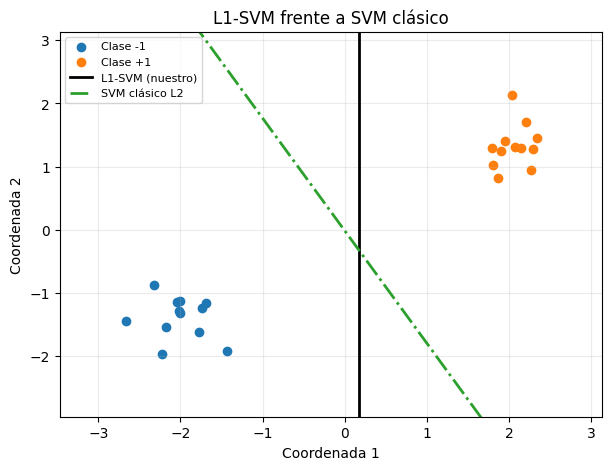

In [21]:
from sklearn.svm import SVC
l2 = SVC(kernel='linear', C=1e6).fit(X, y)       # SVM clásico (norma 2), solo para comparar
w2, b2 = l2.coef_[0], l2.intercept_[0]

def margen(w, b, norma):
    # Distancia del punto más cercano a la recta, dividiendo por la norma indicada.
    return np.min(np.abs(X @ w + b)) / np.linalg.norm(w, norma)

display(pd.DataFrame({
    'w1': [w[0], w2[0]], 'w2': [w[1], w2[1]], 'b': [b_svm, b2],
    'margen medido como el L1-SVM': [margen(w, b_svm, 1), margen(w2, b2, 1)],
    'margen euclídeo (normal)': [margen(w, b_svm, 2), margen(w2, b2, 2)]},
    index=['L1-SVM (nuestro)', 'SVM clásico L2']))

# Dibujo de las dos rectas juntas.
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(*X[y == -1].T, c='tab:blue', label='Clase -1')
ax.scatter(*X[y == 1].T, c='tab:orange', label='Clase +1')
ax.axvline(-b_svm / w[0], color='black', lw=2, label='L1-SVM (nuestro)')     # w2 = 0: recta vertical
xx = np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 100)
ax.plot(xx, -(w2[0] * xx + b2) / w2[1], color='tab:green', lw=2, ls='-.', label='SVM clásico L2')
ax.set_ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
ax.set_xlabel('Coordenada 1'); ax.set_ylabel('Coordenada 2')
ax.set_title('L1-SVM frente a SVM clásico'); ax.legend(fontsize=8); ax.grid(alpha=0.25)
plt.show()

### Conclusiones del apartado 6

* La recta clasifica bien el 100 % de los puntos, y los bordes del margen pasan justo por los vectores soporte.
* Que sea vertical **no es un error**. Cada modelo gana con su propia forma de medir: el L1-SVM tiene más margen con su medida y el clásico tiene más margen euclídeo, como se ve en la tabla. El L1-SVM además ha descartado la coordenada 2 porque no le hacía falta.

## 7. Experimentos extra

### 7.1 Datos en los que hacen falta las dos coordenadas

Generamos dos nubes alargadas y separadas en diagonal. Así ninguna coordenada por sí sola basta para separarlas, y esperamos que ahora $w_1$ y $w_2$ sean distintos de 0. Aquí no imprimimos las iteraciones.

w = [0.4894 0.4847]   b = 0.002   iteraciones: 7


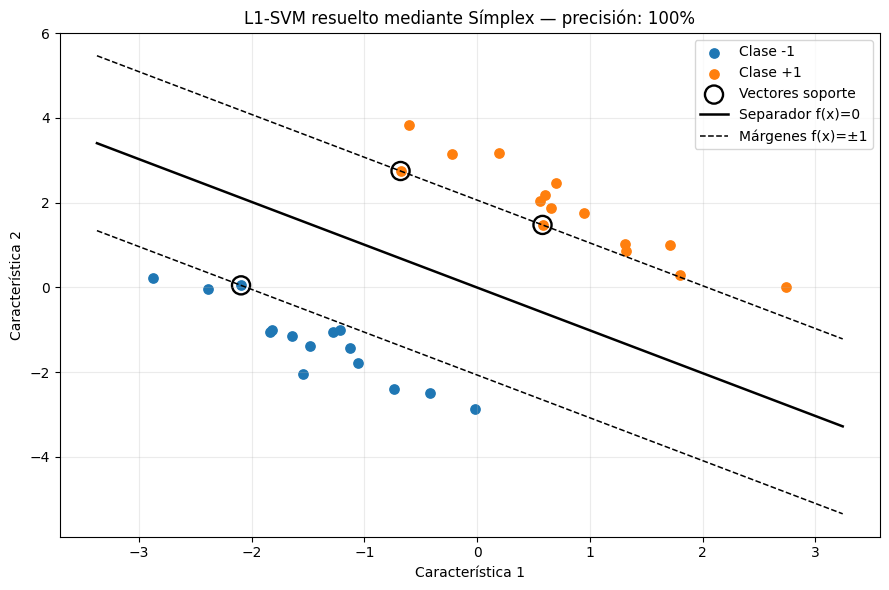

In [22]:
rng = np.random.default_rng(0)
giro = np.array([[1, -1], [1, 1]]) / np.sqrt(2)                 # rotación de 45 grados
neg = rng.normal(size=(15, 2)) * [0.3, 1.6] @ giro.T + [-1.3, -1.3]
pos = rng.normal(size=(15, 2)) * [0.3, 1.6] @ giro.T + [1.3, 1.3]
X2 = np.vstack((neg, pos))
y2 = np.r_[-np.ones(15), np.ones(15)]

# Mismo procedimiento: dual -> Símplex -> w y b desde c_B B^-1.
res2 = simplex(*construir_dual_svm(X2, y2, C), objetivo='max')
w_2, b_2, xi_2 = recuperar_clasificador(res2['multiplicadores'], 2, len(y2))
print('w =', w_2, '  b =', round(b_2, 4), '  iteraciones:', len(res2['historial']) - 1)

prec2 = np.mean(np.where(X2 @ w_2 + b_2 >= 0, 1, -1) == y2)
dibujar_clasificador(X2, y2, w_2, b_2, res2['x'], prec2)

### 7.2 Qué pasa al cambiar $C$

Resolvemos el dual con los datos del apartado 2 para varios valores de $C$, de mayor a menor, y anotamos la recta, la suma de holguras y el número de vectores soporte.

In [ ]:
filas = []
for Cv in [10, 1, 0.1, 0.05, 0.02]:
    res_c = simplex(*construir_dual_svm(X, y, Cv), objetivo='max')
    wc, bc, xic = recuperar_clasificador(res_c['multiplicadores'], d, n)
    filas.append({'C': Cv, 'w1': wc[0], 'w2': wc[1], 'b': bc,
                  'suma de holguras': xic.sum(),
                  'nº vectores soporte': int((res_c['x'] > 1e-7).sum()),
                  'precisión': np.mean(np.where(X @ wc + bc >= 0, 1, -1) == y)})
tabla_C = pd.DataFrame(filas)
reales = tabla_C.select_dtypes(float).columns
tabla_C[reales] = tabla_C[reales].round(4) + 0.0 # redondeo (y quita los -0.0)
display(tabla_C)

,C,w1,w2,b,suma de holguras,nº vectores soporte,precisión
0,10.00,0.6208,0.0,-0.1101,0.0000,2,1.0
1,1.00,0.6208,0.0,-0.1101,0.0000,2,1.0
2,0.10,0.5550,0.0,-0.0340,0.2703,6,1.0
3,0.05,0.4950,0.0,-0.0062,1.1169,12,1.0
4,0.02,0.0000,0.0,1.0000,24.0000,24,0.5


### Conclusiones del apartado 7

* **Dos coordenadas.** Con datos en diagonal el L1-SVM usa las dos coordenadas. La recta vertical del apartado 6 se debía a los datos, no a un fallo.
* **Efecto de $C$.**
  * Con $C$ grande (10 o 1), salirse del margen es muy caro: no hay holguras y solo hay 2 vectores soporte.
  * Al bajar $C$, salirse del margen sale más barato. El margen se ensancha ($w$ más pequeño), aparecen holguras y hay más vectores soporte.
  * Con $C$ demasiado pequeño el modelo "se rinde" ($w=0$) y lo clasifica todo igual.
  * Por eso, con datos separables, conviene usar un $C$ grande.

## 8. Conclusiones generales

Lo que más destaca de los resultados es que el primal y el dual son dos formas de ver el mismo problema, y que el Símplex combinado aprovecha justo esa relación. El primal del SVM busca la recta con las restricciones $y_i(w^Tx_i+b)\ge1$. Al pasarlas a la forma $\le$ los términos independientes quedan negativos, así que $x=0$ no es factible y el algoritmo tiene que empezar con el dual. En el dual del SVM ocurre lo contrario. todos los $b_i$ son no negativos ($1$, $0$ y $C$), $\alpha=0$ ya es factible y basta con el primal. No es casualidad que una formulación arranque bien con un método y la otra con el contrario es la propiedad d dualidad vista desde dentro del algoritmo

La misma idea explica por qué la recta se puede leer de $c_BB^{-1}$. Estos valores son las variables de holhura de las restricciones del dual. dicen cuánto mejoraría el objetivo si cada restricción se relajara un poco. Como esas restricciones salen de las variables del primal, sus precios son exactamente $w^+$, $w^-$, $b^+$, $b^-$ y $\xi$. El Símplex calcula la solución del otro problema sin que se le pida, y que los dos valores óptimos coincidan es la dualidad fuerte comprobada en números.

Los resultados del SVM también dicen mucho ya que de los 24 puntos, solo 2 tienen $\alpha_i\ne0$: son los vectores soporte, los únicos que determinan la recta. El resto podría moverse o eliminarse sin que la solución cambiara. Por eso el Símplex necesita tan pocas iteracione, casi todas las $\alpha_i$ se quedan a 0 y fuera de la base.

La recta vertical, $w=(0.62,\,0)$, es la consecuencia más interesante de usar la norma 1. Minimizar $\|w\|_1$ equivale a maximizar el margen medido en norma $\infty$, y las soluciones de ese problema tienden a caer en las esquinas, es decir, con coordenadas exactamente a 0. Con nuestros datos basta la primera coordenada para separar las clases, así que el modelo descarta la segunda. Si se compara con el SVM clásico de norma 2, cada uno gana en su propia métrica, el L1-SVM tiene más margen en norma $\infty$ (1.61 frente a 1.50) y el L2-SVM más margen euclídeo (2.04 frente a 1.61). Ninguno es "el correcto" ya que responden a preguntas distintas. Cuando los datos están en diagonal y hacen falta las dos coordenadas, el L1-SVM las usa a la vez, $w\approx(0.49,\,0.48)$. Selecciona variables solo cuando puede hacerlo.

Por último, el parámetro $C$ regula el equilibrio entre una recta sencilla (con $\|w\|_1$ pequeña) y clasificar bien los puntos. Con $C$ grande domina el acierto y se obtiene la separación perfecta. Al bajarlo, a $\|w\|_1$ le sale más rentable encogerse que respetar los puntos, y con $C=0.02$ el modelo prefiere $w=0$, lo que deja un clasificador trivial con un 50 % de acierto. En conjunto, la práctica muestra que un SVM no es más que un problema lineal bien planteado, y que interpretar el Símplex (su base, sus holguras y su dual) es interpretar el propio clasificador.
